# Credit Risk Model Analysis
Exploration of the German Credit dataset and of the trained model.
Run from the `notebooks/` folder after training (`python -m app.ml.train` in `backend/`).

In [1]:
import sys, json
sys.path.insert(0, '../backend')
import pandas as pd
import matplotlib.pyplot as plt
from app.config import settings
from app.ml.preprocessing import load_dataset, MODEL_FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET
df = load_dataset(settings.data_path)
df.shape

(1000, 24)

## 1. Dataset overview

In [2]:
print('Missing values:', int(df.isna().sum().sum()))
print('Bad credit rate:', df[TARGET].mean())
df[NUMERIC_FEATURES].describe().T

Missing values: 0
Bad credit rate: 0.3


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


In [3]:
for col in ['checking_status', 'credit_history', 'savings_status']:
    print(df.groupby(col)[TARGET].agg(['count', 'mean']).rename(columns={'mean': 'bad_rate'}).round(3), '\n')

                             count  bad_rate
checking_status                             
0 - 200 DM                     269     0.390
< 0 DM                         274     0.493
>= 200 DM / salary assigned     63     0.222
no checking account            394     0.117 

                                            count  bad_rate
credit_history                                             
all credits at this bank paid back duly        49     0.571
critical account / other credits elsewhere    293     0.171
delay in paying off in the past                88     0.318
existing credits paid back duly till now      530     0.319
no credits / all paid back duly                40     0.625 

                              count  bad_rate
savings_status                               
100 - 500 DM                    103     0.330
500 - 1000 DM                    63     0.175
< 100 DM                        603     0.360
>= 1000 DM                       48     0.125
unknown / no savings account  

## 2. Sensitive attributes (not used by the model)

In [4]:
for col in ['sex', 'age_group', 'foreign_worker_group']:
    print(df.groupby(col)[TARGET].agg(['count', 'mean']).rename(columns={'mean': 'bad_rate'}).round(3), '\n')

        count  bad_rate
sex                    
female    310     0.352
male      690     0.277 

             count  bad_rate
age_group                   
25 and over    851     0.281
under 25       149     0.409 

                      count  bad_rate
foreign_worker_group                 
foreign worker          963     0.307
not foreign worker       37     0.108 



## 3. Model comparison (from training run)

In [5]:
meta = json.load(open(settings.model_dir / 'metadata.json'))
print('Selected:', meta['selected_model']); print(meta['selection_reason'])
pd.DataFrame(meta['comparison']).drop(columns=['confusion_matrix', 'best_params']).set_index('model')

Selected: Random Forest
XGBoost had the highest CV ROC-AUC (0.7987), but Random Forest (0.7923) is within 0.01 and is simpler and more interpretable, so it was preferred.


,cv_roc_auc,threshold,accuracy,precision,recall,f1,roc_auc,misclassification_cost
model,,,,,,,,
Logistic Regression,0.7749,0.5,0.770,0.6944,0.4167,0.5208,0.8094,186
Random Forest,0.7923,0.5,0.765,0.7241,0.3500,0.4719,0.8093,203
XGBoost,0.7987,0.5,0.775,0.6744,0.4833,0.5631,0.8015,169


In [6]:
pd.Series({k: v for k, v in meta['selected_metrics'].items() if k != 'confusion_matrix'})

threshold                   0.2700
accuracy                    0.6400
precision                   0.4474
recall                      0.8500
f1                          0.5862
roc_auc                     0.8093
misclassification_cost    108.0000
dtype: float64

## 4. Global SHAP importance

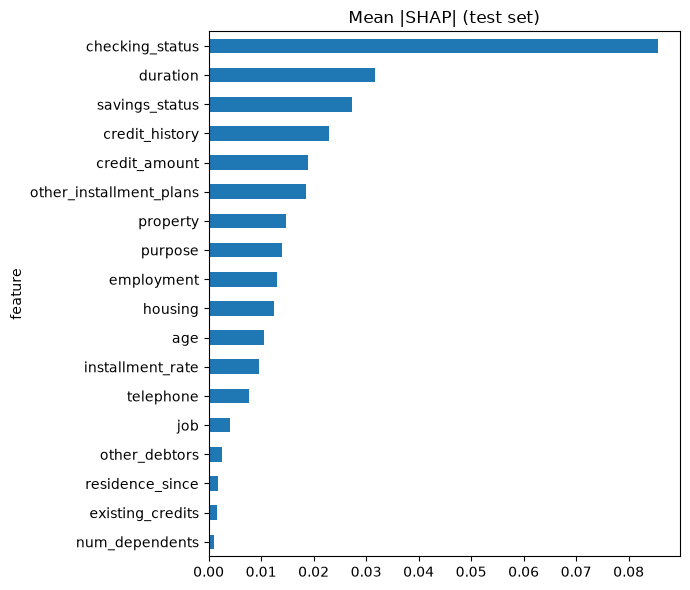

In [7]:
imp = pd.DataFrame(meta['global_importance']).set_index('feature')['mean_abs_shap'].sort_values()
imp.plot.barh(figsize=(7, 6), title='Mean |SHAP| (test set)'); plt.tight_layout(); plt.show()

## 5. Fairness audit

In [8]:
from app.services.fairness_service import fairness_report
rep = fairness_report()
for a in rep['attributes']:
    print(a['attribute'], a['status'], 'DPD=', a['demographic_parity_difference'], 'EOD=', a['equalized_odds_difference'])
    print(pd.DataFrame(a['groups']).set_index('group'), '\n')

/home/claude/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sex NEEDS ATTENTION DPD= 0.029 EOD= 0.15
        count  approval_rate  actual_good_rate  false_positive_rate  \
group                                                                 
female     61         0.4098            0.6721               0.5122   
male      139         0.4388            0.7122               0.4242   

        false_negative_rate  accuracy  
group                                  
female                 0.25    0.5738  
male                   0.10    0.6691   

age_group CONCERNING DPD= 0.2475 EOD= 0.2917
             count  approval_rate  actual_good_rate  false_positive_rate  \
group                                                                      
25 and over    161         0.4783            0.7453               0.4083   
under 25        39         0.2308            0.5128               0.7000   

             false_negative_rate  accuracy  
group                                       
25 and over               0.1463    0.6584  
under 25                  0

## 6. Example local explanation and stability

In [9]:
from app.services.prediction_service import predict
from app.services.stability_service import analyse
applicant = df[MODEL_FEATURES].iloc[1].to_dict()
res = predict(applicant)
print(res['summary'])
pd.DataFrame(res['top_factors'])[['label', 'value', 'shap_value']]

The model estimates a 38% probability of default (decision threshold 27%), so the applicant is classed as HIGH RISK, mainly because of: Loan duration (months), Checking account balance.


,label,value,shap_value
0,Loan duration (months),48,0.0691
1,Checking account balance,0 - 200 DM,0.0328
2,Savings balance,< 100 DM,0.0325
3,Most valuable property,real estate,-0.0323
4,Age,22,0.0210


In [10]:
s = analyse(applicant)
print(s['interpretation'])

20 of 20 slightly modified versions of this applicant (±5% noise on loan duration and amount) received the same decision (100%). The applicant's default probability (38%) is 11% away from the decision threshold (27%). No single small change flipped the decision.
